# 01 · Dataset overview

**Goal:** check the whole dataset at once. Does every child have the same channels? Are the two groups recorded for the same length of time?

**How it fits the project:** a classifier can look clever by using a **shortcut**, something that differs between groups but is not brain activity. Here is an analogy. If every patient on one ward wears a blue gown, a model can "diagnose" by gown colour. Recording length is such a possible shortcut. Measuring how well length *alone* predicts the group gives a **baseline**: an EEG model must beat it to show it uses the brain signal.

**Question:** Do all children have 19 channels, and is recording length similar in both groups?

**How:**
1. `list_children()` (from `src/load.py`) builds a table with one row per child: ID, group, label (1 = ADHD, 0 = Control) and file path.
2. `assert ... is_unique` stops the notebook if two files share an ID. This matters because we later split by child.
3. For every child we load the file and store the number of channels (`shape[0]`) and the length in seconds (samples ÷ 128).
4. `value_counts` counts how often each channel number appears. `groupby("group").describe()` gives count, mean, std, min, quartiles (25%, 50% = median, 75%) and max for each group.
5. A box plot: the box spans the middle 50% of children, the line inside is the median, and the whiskers and dots show the spread and outliers.

**What we found:** All 121 children have 19 channels and the IDs are unique. **ADHD recordings are longer**: median 143.7 s vs 122.1 s (mean 154.6 vs 124.9). They also vary much more (std 58.1 vs 29.9; longest 338 s vs 203 s). We do not know why. One possible reason (an **assumption**): if the task ends when the child finishes, slower or more distracted children record for longer. Either way, length is not brain activity, but it differs between the groups.

n_channels
19    121
Name: count, dtype: int64
         count   mean   std   min    25%    50%    75%    max
group                                                        
ADHD      61.0  154.6  58.1  72.5  111.8  143.7  185.0  337.9
Control   60.0  124.9  29.9  62.4  104.6  122.1  139.1  203.0


<Axes: title={'center': 'seconds'}, xlabel='group'>

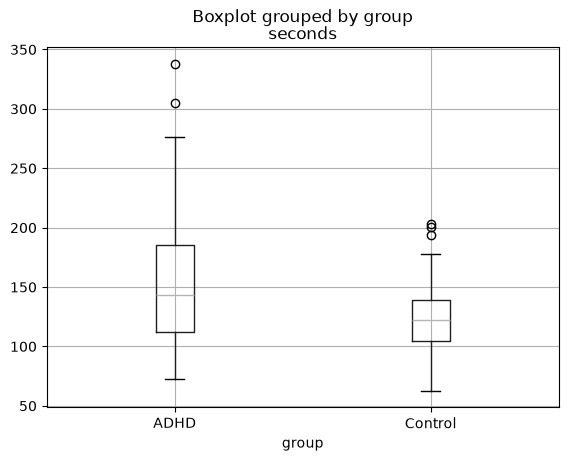

In [1]:
import sys; sys.path.append("..")
import pandas as pd
from src.load import list_children, load_child
from src.channels import SFREQ

df = pd.DataFrame(list_children())
assert df.child_id.is_unique, "two children share an id!"
df["n_channels"] = [load_child(p).shape[0] for p in df.path]
df["seconds"]    = [load_child(p).shape[1] / SFREQ for p in df.path]

print(df.n_channels.value_counts())
print(df.groupby("group").seconds.describe().round(1))
df.boxplot(column="seconds", by="group")

**Question:** Can recording length alone tell ADHD from Control?

**How:**
1. **Logistic regression** fits an S-shaped curve that turns the input (seconds) into a probability of ADHD.
2. `cross_val_score(..., cv=5)` is **5-fold cross-validation**. It splits the children into 5 parts, trains on 4 and tests on the 5th, and repeats so every child is tested once. For classifiers, scikit-learn keeps the ADHD/Control mix about the same in each part (stratified). One row = one child here, so this is already a child-level split.
3. `scoring="roc_auc"` uses **AUC** (area under the ROC curve). AUC is the chance that a randomly chosen ADHD child gets a higher score than a randomly chosen Control child. 0.5 = coin flip and 1.0 = perfect. Unlike accuracy, AUC does not depend on picking a cut-off.

**What we found:** **AUC 0.65 ± 0.17** (mean ± std over the 5 folds). Recording length alone predicts the group better than chance. This is the bar: an EEG model must clearly beat 0.65 to show it uses brain information rather than length. The ± is large because each test part has only about 24 children.

In [2]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

auc = cross_val_score(LogisticRegression(), df[["seconds"]], df.label,
                      cv=5, scoring="roc_auc")
print("Length-only AUC:", auc.mean().round(2), "±", auc.std().round(2))

Length-only AUC: 0.65 ± 0.17


## Key takeaways
- All 121 children have 19 channels and unique IDs.
- ADHD recordings are longer and more variable (median 144 s vs 122 s).
- Length alone gives AUC 0.65. This is a non-brain shortcut and the baseline to beat.
- Length can sneak into other analyses. For example, longer recordings give more 4-second windows (see notebook 03).

## Open questions
- Why are ADHD recordings longer? Check the dataset description (task design, stopping rule).
- Should we crop every recording to the same length (the shortest is 62.4 s) to remove this shortcut?
- Does having more windows per ADHD child bias window-level models?